<a href="https://colab.research.google.com/github/Granolabar36/NEUR-3002/blob/main/ica4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BIOPHYSICAL SOMATOSENSORY RATE-CODED POPULATION SIMULATION
True Direction       : 120.0°
Decoded Direction (θ̂): 125.9°
Estimation Error     : 5.92°
Population Vector D  : [-48.36, 66.75] (Magnitude = 82.43)
-----------------------------------------------------------------
Neuron | Pref θ_i | Spikes Count | Discharge Rate r_i (Hz)
   1   |    0.0°  |      0       |        0.0 Hz
   2   |   45.0°  |      1       |        4.2 Hz
   3   |   90.0°  |      4       |       16.7 Hz
   4   |  135.0°  |     16       |       66.7 Hz
   5   |  180.0°  |      1       |        4.2 Hz
   6   |  225.0°  |      0       |        0.0 Hz
   7   |  270.0°  |      0       |        0.0 Hz
   8   |  315.0°  |      0       |        0.0 Hz


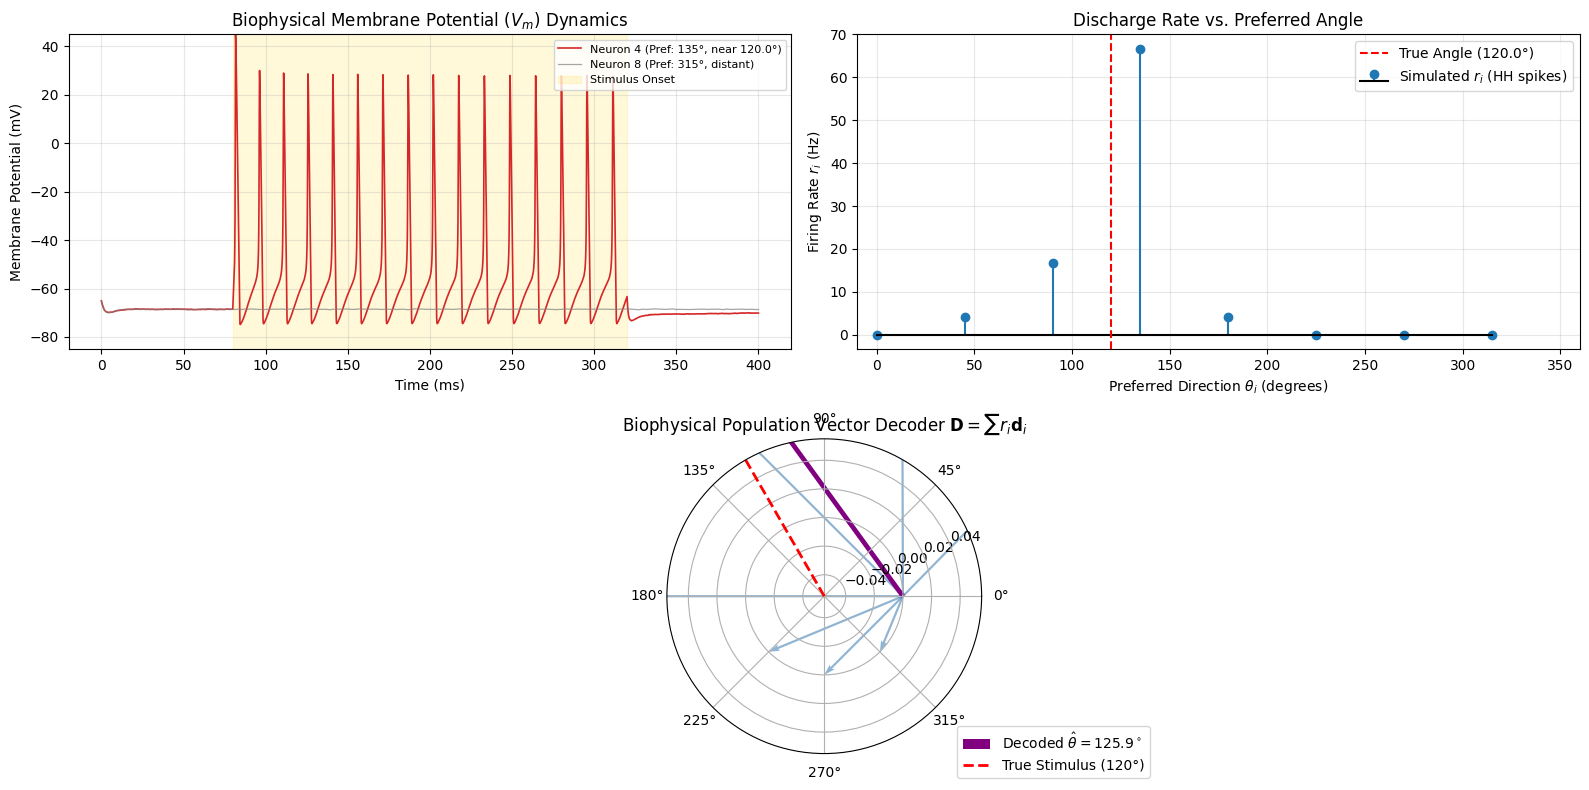

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# =============================================================================
# BIOLOGICALLY REALISTIC SOMATOSENSORY POPULATION RATE CODING MODEL
# Integrates biophysical mechanisms highlighted in the lecture:
# 1. Full Hodgkin-Huxley conductance dynamics (Na+, K+, Leak channels)[cite: 1]
# 2. Neuromodulation shifting baseline Vm (-70 mV to -60 mV) and excitability[cite: 1]
# 3. Calcium-activated K+ current (I_K,Ca) causing spike frequency adaptation[cite: 1]
# 4. Mechanoreceptive receptive field tuning (indentation direction)[cite: 1]
# 5. Population vector decoding of firing rates r_i[cite: 1]
# =============================================================================

class BiophysicalSomatosensoryNeuron:
    """
    Hodgkin-Huxley style neuron with voltage-gated Na+, delayed-rectifier K+,
    leak, and a calcium-activated K+ current (I_K,Ca) responsible for
    spike-frequency accommodation / adaptation (Slowly vs Rapidly Adapting)[cite: 1].
    """
    def __init__(self, preferred_angle_rad, neuromodulated=False, adaptation_type="SA"):
        self.theta_pref = preferred_angle_rad
        self.adaptation_type = adaptation_type  # 'SA' (Slowly Adapting) or 'RA' (Rapidly Adapting)[cite: 1]

        # Membrane capacitance (uF/cm^2)
        self.C_m = 1.0

        # Maximum channel conductances (mS/cm^2)
        self.g_Na = 120.0     # Voltage-gated Sodium channels (AIS/soma)[cite: 1]
        self.g_K = 36.0       # Delayed rectifier Potassium channels[cite: 1]
        self.g_L = 0.3        # Leak channels[cite: 1]

        # Reversal potentials (mV)
        self.E_Na = 50.0
        self.E_K = -77.0

        # Neuromodulators change the ratio of leak/gated channels and resting Vm[cite: 1]
        # Resting potential shifts from -70 mV up to -60 mV under monoamines/ACh[cite: 1]
        if neuromodulated:
            self.E_L = -58.0  # Depolarized resting equilibrium[cite: 1]
            # Neuromodulators (5-HT/NE) block I_K,Ca to permit sustained firing[cite: 1]
            self.g_KCa = 0.05
        else:
            self.E_L = -65.0  # Standard rest (~ -70 mV effective rest)[cite: 1]
            # Rapidly adapting receptors have strong adaptation currents[cite: 1]
            self.g_KCa = 0.8 if adaptation_type == "RA" else 0.25

        # Calcium dynamics for I_K,Ca (accommodation)[cite: 1]
        self.E_Ca = 120.0
        self.g_Ca = 0.08
        self.tau_Ca = 80.0    # Ca2+ removal time constant (ms)
        self.Ca = 0.0001      # Intracellular [Ca2+] (mM)

        # Initial state variables (resting equilibrium)
        self.V = -65.0        # Membrane potential (mV)[cite: 1]
        self.m = self.alpha_m(self.V) / (self.alpha_m(self.V) + self.beta_m(self.V))
        self.h = self.alpha_h(self.V) / (self.alpha_h(self.V) + self.beta_h(self.V))
        self.n = self.alpha_n(self.V) / (self.alpha_n(self.V) + self.beta_n(self.V))

    # --- Hodgkin-Huxley Rate Constants ---
    @staticmethod
    def alpha_m(V):
        v = V + 40.0
        return 0.1 * v / (1.0 - np.exp(-v / 10.0)) if abs(v) > 1e-5 else 1.0

    @staticmethod
    def beta_m(V):
        return 4.0 * np.exp(-(V + 65.0) / 18.0)

    @staticmethod
    def alpha_h(V):
        return 0.07 * np.exp(-(V + 65.0) / 20.0)

    @staticmethod
    def beta_h(V):
        return 1.0 / (1.0 + np.exp(-(V + 35.0) / 10.0))

    @staticmethod
    def alpha_n(V):
        v = V + 55.0
        return 0.01 * v / (1.0 - np.exp(-v / 10.0)) if abs(v) > 1e-5 else 0.1

    @staticmethod
    def beta_n(V):
        return 0.125 * np.exp(-(V + 65.0) / 80.0)

    def receptive_field_current(self, stimulus_angle_rad, stimulus_amp=18.0):
        """
        Receptive field tuning: Transduces stimulus direction into injected synaptic/generator current[cite: 1].
        """
        ang_diff = np.arctan2(np.sin(stimulus_angle_rad - self.theta_pref),
                              np.cos(stimulus_angle_rad - self.theta_pref))
        tuning_width = np.deg2rad(45.0)
        # Gaussian sensory drive[cite: 1]
        I_stim = stimulus_amp * np.exp(-0.5 * (ang_diff / tuning_width) ** 2)
        return I_stim

    def step(self, dt, I_inj):
        """
        Integrates one time step (Euler forward) through conductances and membrane capacitance[cite: 1].
        """
        # Thermal channel noise (fluctuation in open channels)[cite: 1]
        noise = np.random.normal(0, 0.4)

        # 1. Voltage-gated gating updates
        self.m += dt * (self.alpha_m(self.V) * (1.0 - self.m) - self.beta_m(self.V) * self.m)
        self.h += dt * (self.alpha_h(self.V) * (1.0 - self.h) - self.beta_h(self.V) * self.h)
        self.n += dt * (self.alpha_n(self.V) * (1.0 - self.n) - self.beta_n(self.V) * self.n)

        # 2. Channel currents (uA/cm^2)
        I_Na = self.g_Na * (self.m ** 3) * self.h * (self.V - self.E_Na)   # Fast Na+[cite: 1]
        I_K  = self.g_K * (self.n ** 4) * (self.V - self.E_K)              # Delayed Rectifier K+[cite: 1]
        I_L  = self.g_L * (self.V - self.E_L)                               # Leak current[cite: 1]

        # Calcium entry during spike & Ca-activated K+ current (accommodation)[cite: 1]
        m_ca = 1.0 / (1.0 + np.exp(-(self.V + 20.0) / 9.0))
        I_Ca = self.g_Ca * (m_ca ** 2) * (self.V - self.E_Ca)
        o_kca = self.Ca / (self.Ca + 0.03)  # activation fraction of I_K,Ca
        I_KCa = self.g_KCa * o_kca * (self.V - self.E_K)                    # I_K,Ca current[cite: 1]

        # 3. Calcium concentration update
        self.Ca += dt * (-0.002 * I_Ca - (self.Ca - 0.0001) / self.tau_Ca)

        # 4. Membrane potential update (dInflow = -sum(I_ionic) + I_inj)[cite: 1]
        dV = (I_inj + noise - (I_Na + I_K + I_L + I_KCa)) / self.C_m
        self.V += dt * dV

        return self.V


# =============================================================================
# POPULATION VECTOR DECODER
# =============================================================================
def decode_population(preferred_angles_rad, firing_rates):
    """
    Computes Georgopoulos Population Vector from biophysical firing rates r_i[cite: 1]:
    D = sum(r_i * d_i) where d_i = [cos(theta_i), sin(theta_i)][cite: 1]
    theta_hat = arctan2(D_y, D_x)[cite: 1]
    """
    Dx = np.sum(firing_rates * np.cos(preferred_angles_rad))
    Dy = np.sum(firing_rates * np.sin(preferred_angles_rad))
    decoded_angle = np.arctan2(Dy, Dx) % (2.0 * np.pi)
    magnitude = np.hypot(Dx, Dy)
    return np.array([Dx, Dy]), magnitude, np.rad2deg(decoded_angle)


# =============================================================================
# SIMULATION EXPERIMENT
# =============================================================================
if __name__ == "__main__":
    np.random.seed(42)

    # Simulation setup
    dt = 0.02          # 0.02 ms integration step
    T_total = 400.0    # 400 ms duration
    t = np.arange(0, T_total, dt)
    stim_start, stim_end = 80.0, 320.0

    # 8 sensory neurons covering 360 degrees of skin directional stretch[cite: 1]
    n_neurons = 8
    pref_angles_deg = np.linspace(0, 360, n_neurons, endpoint=False)
    pref_angles_rad = np.deg2rad(pref_angles_deg)

    # True directional skin deflection angle
    true_direction_deg = 120.0
    true_direction_rad = np.deg2rad(true_direction_deg)

    # Instantiate population of biophysical neurons
    population = [
        BiophysicalSomatosensoryNeuron(pref_angles_rad[i], neuromodulated=False, adaptation_type="SA")
        for i in range(n_neurons)
    ]

    # Voltage recording matrix [neurons x timesteps]
    V_traces = np.zeros((n_neurons, len(t)))
    spike_counts = np.zeros(n_neurons)

    # Run Hodgkin-Huxley time stepping
    for step_idx, current_time in enumerate(t):
        is_stim_on = stim_start <= current_time <= stim_end

        for i, neuron in enumerate(population):
            # Transduce stimulus via receptive field into generator current[cite: 1]
            I_transduced = neuron.receptive_field_current(true_direction_rad) if is_stim_on else 0.0

            # Integrate membrane potential with all ion channels
            V_prev = neuron.V
            V_curr = neuron.step(dt, I_transduced)
            V_traces[i, step_idx] = V_curr

            # Detect spikes at AIS (crosses threshold of 0 mV)[cite: 1]
            if V_prev < 0.0 and V_curr >= 0.0 and is_stim_on:
                spike_counts[i] += 1

    # Firing rates in Hz (spikes/second during stimulus window)[cite: 1]
    stim_duration_sec = (stim_end - stim_start) / 1000.0
    firing_rates = spike_counts / stim_duration_sec

    # Decode target direction from biophysical population
    D_vec, D_mag, decoded_deg = decode_population(pref_angles_rad, firing_rates)

    print("=" * 65)
    print("BIOPHYSICAL SOMATOSENSORY RATE-CODED POPULATION SIMULATION")
    print("=" * 65)
    print(f"True Direction       : {true_direction_deg:.1f}°")
    print(f"Decoded Direction (θ̂): {decoded_deg:.1f}°")
    print(f"Estimation Error     : {abs(decoded_deg - true_direction_deg):.2f}°")
    print(f"Population Vector D  : [{D_vec[0]:.2f}, {D_vec[1]:.2f}] (Magnitude = {D_mag:.2f})")
    print("-" * 65)
    print("Neuron | Pref θ_i | Spikes Count | Discharge Rate r_i (Hz)")
    for i in range(n_neurons):
        print(f"  {i+1:2d}   |  {pref_angles_deg[i]:5.1f}°  |     {int(spike_counts[i]):2d}       |     {firing_rates[i]:6.1f} Hz")
    print("=" * 65)

    # =============================================================================
    # PLOTTING
    # =============================================================================
    fig = plt.figure(figsize=(16, 8))

    # 1. Action Potential Traces (Neuron with closest preference vs distant)
    best_neuron_idx = np.argmin(np.abs(pref_angles_deg - true_direction_deg))
    distant_neuron_idx = (best_neuron_idx + 4) % n_neurons

    ax1 = plt.subplot(2, 2, 1)
    ax1.plot(t, V_traces[best_neuron_idx], "tab:red", lw=1.2,
             label=f"Neuron {best_neuron_idx+1} (Pref: {pref_angles_deg[best_neuron_idx]:.0f}°, near {true_direction_deg}°)")
    ax1.plot(t, V_traces[distant_neuron_idx], "gray", lw=0.9, alpha=0.7,
             label=f"Neuron {distant_neuron_idx+1} (Pref: {pref_angles_deg[distant_neuron_idx]:.0f}°, distant)")
    ax1.axvspan(stim_start, stim_end, color="gold", alpha=0.15, label="Stimulus Onset")
    ax1.set_title("Biophysical Membrane Potential ($V_m$) Dynamics")
    ax1.set_xlabel("Time (ms)")
    ax1.set_ylabel("Membrane Potential (mV)")
    ax1.set_ylim(-85, 45)
    ax1.legend(loc="upper right", fontsize=8)
    ax1.grid(True, alpha=0.3)

    # 2. Rate Coding Bar/Stem Plot
    ax2 = plt.subplot(2, 2, 2)
    ax2.stem(pref_angles_deg, firing_rates, linefmt="C0-", markerfmt="C0o", basefmt="k-", label="Simulated $r_i$ (HH spikes)")
    ax2.axvline(true_direction_deg, color="red", linestyle="--", label=f"True Angle ({true_direction_deg}°)")
    ax2.set_title("Discharge Rate vs. Preferred Angle")
    ax2.set_xlabel("Preferred Direction $\\theta_i$ (degrees)")
    ax2.set_ylabel("Firing Rate $r_i$ (Hz)")
    ax2.set_xlim(-10, 360)
    ax2.grid(True, alpha=0.3)
    ax2.legend()

    # 3. Vector Addition & Decoding (Polar)
    ax3 = plt.subplot(2, 1, 2, polar=True)
    for i in range(n_neurons):
        ax3.quiver(0, 0, pref_angles_rad[i], firing_rates[i],
                   angles="xy", scale_units="xy", scale=1, color="steelblue", alpha=0.6, width=0.007)

    # Decoded vector D
    ax3.quiver(0, 0, np.deg2rad(decoded_deg), np.max(firing_rates),
               angles="xy", scale_units="xy", scale=1, color="purple", width=0.015,
               label=f"Decoded $\\hat{{\\theta}} = {decoded_deg:.1f}^\\circ$")
    ax3.axvline(true_direction_rad, color="red", linestyle="--", lw=2,
                label=f"True Stimulus ({true_direction_deg:.0f}°)")
    ax3.set_title("Biophysical Population Vector Decoder $\\mathbf{D} = \\sum r_i \\mathbf{d}_i$")
    ax3.legend(loc="lower left", bbox_to_anchor=(0.9, -0.1))

    plt.tight_layout()
    plt.show()